# 🚗 Análisis de Severidad de Siniestros Automotrices en México (2020-2024)
## Modelo Actuarial de Tarificación Técnica, Fuentes INEGI y Drivers de Impacto

---
### 📋 Estructura del Notebook:
1. **Importación de Librerías y Configuración**
2. **Ingesta de Fuentes de Datos** (Baseline Chubb + INEGI Censo/VMRC + Mercado Libre / CNE)
3. **Supuestos de Negocio y Transformación Actuarial**
4. **Resultados Principales: Top 3 Estados con Mayor Severidad**
5. **Cálculo de 4 Métricas Simples de Alto Valor**
6. **Análisis de Correlación** (Top 3 Variables de Impacto en Severidad)
7. **Visualizaciones Gráficas Ejecutivas (Dashboards de Métricas Simples)**
8. **Conclusiones Estratégicas y Recomendaciones**
9. **🤖 Agente de IA Conversacional (Llama-3 LLM & Fuzzy Matching con Resiliencia Ortográfica)**

## 1. Importación de Librerías y Configuración del Entorno

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import difflib
import unicodedata

# Configuración visual de alta calidad
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print("✅ Librerías cargadas exitosamente.")

✅ Librerías cargadas exitosamente.


## 2. Ingesta de Fuentes de Datos

Integramos dos fuentes de información:
1. **Baseline de Siniestros de Chubb (2020-2024)**: Contiene el costo acumulado de siniestros ocurridos en Millones de Pesos (MDP) por estado y año.
2. **Fuentes Complementarias (INEGI & Colab Pipeline)**:
   - **INEGI Censo 2020**: Población total por estado.
   - **INEGI VMRC**: Parque vehicular de automóviles particulares registrados en circulación.
   - **INEGI Marco Geoestadístico**: Área geográfica territorial en $\text{km}^2$.
   - **Mercado Libre (Colab)**: Precio de lista promedio de automóviles por estado.
   - **CNE / CRE (Colab)**: Precio promedio de combustible regular por litro.

In [2]:
# 2.1 Carga de Baseline de Siniestros
df_claims = pd.read_csv('data/baseline_siniestros.csv')
df_claims['entidad'] = df_claims['entidad'].str.strip()
df_claims['costo_total_pesos'] = df_claims['siniestros_ocurridos_mdp'] * 1_000_000

# 2.2 Ingesta de Indicadores INEGI y Regionales por Estado
inegi_data = {
    'entidad': [
        'Aguascalientes', 'Baja California', 'Baja California Sur', 'Campeche', 'Chiapas',
        'Chihuahua', 'Ciudad de Mexico', 'Coahuila', 'Colima', 'Durango',
        'Estado de Mexico', 'Guanajuato', 'Guerrero', 'Hidalgo', 'Jalisco',
        'Michoacan', 'Morelos', 'Nayarit', 'Nuevo Leon', 'Oaxaca',
        'Puebla', 'Queretaro', 'Quintana Roo', 'San Luis Potosi', 'Sinaloa',
        'Sonora', 'Tabasco', 'Tamaulipas', 'Tlaxcala', 'Veracruz',
        'Yucatan', 'Zacatecas'
    ],
    'poblacion_2020': [
        1425607, 3769020, 798447, 928363, 5543828,
        3741869, 9209944, 3146771, 731391, 1832650,
        16992418, 6166934, 3540685, 3082841, 8348151,
        4748846, 1971520, 1235456, 5784442, 4132148,
        6583278, 2368467, 1857985, 2822255, 3026943,
        2944840, 2402598, 3527735, 1342977, 8062579,
        2320898, 1622138
    ],
    'automoviles_registrados': [
        541200, 1385400, 395000, 245000, 680000,
        1450000, 5450000, 1150000, 285000, 490000,
        5850000, 1920000, 620000, 690000, 3420000,
        1250000, 510000, 340000, 2580000, 590000,
        1480000, 890000, 610000, 820000, 1050000,
        1180000, 530000, 1120000, 380000, 1750000,
        840000, 460000
    ],
    'area_km2': [
        5616, 71450, 73909, 57507, 73289,
        247455, 1485, 151563, 5625, 123317,
        22357, 30608, 63621, 20813, 78588,
        58643, 4893, 27815, 64210, 93757,
        34251, 11684, 44707, 60983, 57377,
        179355, 24738, 80249, 3991, 71820,
        39612, 75539
    ],
    'precio_gasolina_reg_prom': [
        22.45, 21.80, 23.50, 23.80, 22.90,
        21.90, 23.10, 22.30, 22.80, 23.40,
        22.20, 22.60, 23.90, 22.10, 23.20,
        22.70, 22.50, 23.10, 23.40, 23.60,
        22.30, 22.70, 23.60, 22.80, 23.30,
        22.10, 22.80, 21.95, 22.05, 22.95,
        23.00, 23.20
    ],
    'precio_promedio_auto_ml_k_mxn': [
        245, 260, 280, 230, 215,
        275, 340, 270, 250, 240,
        290, 265, 220, 235, 310,
        240, 255, 235, 330, 210,
        250, 305, 270, 255, 260,
        265, 240, 255, 225, 245,
        275, 230
    ]
}

df_inegi = pd.DataFrame(inegi_data)
df_merged = pd.merge(df_claims, df_inegi, on='entidad', how='left')
print(f"✅ Dataset unificado creado con {len(df_merged)} registros (32 estados × 5 años).")
df_merged.head(3)

✅ Dataset unificado creado con 160 registros (32 estados × 5 años).


,anio,entidad,siniestros_ocurridos_mdp,numero_siniestros_asegurados,costo_total_pesos,poblacion_2020,automoviles_registrados,area_km2,precio_gasolina_reg_prom,precio_promedio_auto_ml_k_mxn
0,2020,Aguascalientes,636.575885,NaN,6.365759e+08,1425607,541200,5616,22.45,245
1,2020,Baja California,1510.667303,NaN,1.510667e+09,3769020,1385400,71450,21.80,260
2,2020,Baja California Sur,381.050698,NaN,3.810507e+08,798447,395000,73909,23.50,280


## 3. Supuestos de Negocio y Transformaciones Actuariales

Aplicamos las fórmulas acordadas con negocio:
- **Riesgo Expuesto**: $35\%$ de la población está asegurada.
- **Número de Reclamos**: $30\%$ de los asegurados tiene un siniestro.
- **Severidad**: $\text{Severidad} = \frac{\text{Costo Total de Siniestros (Pesos)}}{\text{Número de Reclamos}}$
- **Frecuencia**: $\text{Frecuencia} = \frac{\text{Número de Reclamos}}{\text{Riesgo Expuesto}} = 30.0\%$
- **Prima Pura de Riesgo**: $\text{Prima Pura} = \text{Frecuencia} \times \text{Severidad} = \frac{\text{Costo Total de Siniestros}}{\text{Riesgo Expuesto}}$

In [3]:
# Cálculo de variables actuariales
df_merged['riesgo_expuesto'] = df_merged['poblacion_2020'] * 0.35
df_merged['numero_reclamos'] = df_merged['riesgo_expuesto'] * 0.30
df_merged['severidad'] = df_merged['costo_total_pesos'] / df_merged['numero_reclamos']
df_merged['frecuencia'] = 0.30
df_merged['prima_pura_riesgo'] = df_merged['frecuencia'] * df_merged['severidad']

# Variables complementarias derivadas
df_merged['densidad_poblacional'] = df_merged['poblacion_2020'] / df_merged['area_km2']
df_merged['autos_por_1000_hab'] = (df_merged['automoviles_registrados'] / df_merged['poblacion_2020']) * 1000

df_merged[['anio', 'entidad', 'siniestros_ocurridos_mdp', 'riesgo_expuesto', 'numero_reclamos', 'severidad', 'prima_pura_riesgo']].head()

,anio,entidad,siniestros_ocurridos_mdp,riesgo_expuesto,numero_reclamos,severidad,prima_pura_riesgo
0,2020,Aguascalientes,636.575885,498962.45,149688.735,4252.663936,1275.799181
1,2020,Baja California,1510.667303,1319157.00,395747.100,3817.254259,1145.176278
2,2020,Baja California Sur,381.050698,279456.45,83836.935,4545.141088,1363.542327
3,2020,Campeche,319.890289,324927.05,97478.115,3281.662648,984.498794
4,2020,Chiapas,1031.233262,1940339.80,582101.940,1771.568159,531.470448


## 4. Resultados Principales: Top 3 Estados con Mayor Severidad

Agrupamos los datos promedio para el periodo 2020-2024 e identificamos las entidades con mayor severidad por siniestro.

In [4]:
# Agrupación por Estado
df_resumen_estado = df_merged.groupby('entidad').agg({
    'siniestros_ocurridos_mdp': 'mean',
    'costo_total_pesos': 'mean',
    'severidad': 'mean',
    'prima_pura_riesgo': 'mean',
    'poblacion_2020': 'first',
    'automoviles_registrados': 'first',
    'precio_promedio_auto_ml_k_mxn': 'first',
    'autos_por_1000_hab': 'first',
    'densidad_poblacional': 'first'
}).reset_index()

# Ordenar por Severidad
df_resumen_estado = df_resumen_estado.sort_values(by='severidad', ascending=False)
top3_estados = df_resumen_estado.head(3)

print("🏆 === TOP 3 ESTADOS CON MAYOR SEVERIDAD DE SINIESTROS ===")
for idx, row in top3_estados.iterrows():
    print(f"• {row['entidad']}: Severidad = ${row['severidad']:,.2f} MXN | Prima Pura = ${row['prima_pura_riesgo']:,.2f} MXN | Costo Anual MDP = ${row['siniestros_ocurridos_mdp']:,.2f} MDP")

🏆 === TOP 3 ESTADOS CON MAYOR SEVERIDAD DE SINIESTROS ===
• Nuevo Leon: Severidad = $13,970.61 MXN | Prima Pura = $4,191.18 MXN | Costo Anual MDP = $8,485.28 MDP
• Sinaloa: Severidad = $11,637.24 MXN | Prima Pura = $3,491.17 MXN | Costo Anual MDP = $3,698.65 MDP
• Queretaro: Severidad = $11,476.31 MXN | Prima Pura = $3,442.89 MXN | Costo Anual MDP = $2,854.03 MDP


## 5. Cálculo de 4 Métricas Simples de Alto Valor

Calculamos 4 indicadores muy fáciles de explicar que potencian el análisis directamente con los datos actuales:
1. **Índice de Severidad Relativa (Nacional = 100)**: Cuántas veces supera cada estado el promedio nacional.
2. **Crecimiento Acumulado de Severidad (2020 a 2024 %)**: Velocidad a la que se incrementa el costo por siniestro.
3. **Costo por Automóvil Registrado ($/auto)**: Costo monetario medio por vehículo en circulación.
4. **Concentración Nacional del Costo de Siniestralidad (% Pareto)**: % de la bolsa nacional que representa cada estado.

In [5]:
# 5.1 Crecimiento de Severidad (2020 a 2024)
df_2020_sev = df_merged[df_merged['anio'] == 2020].set_index('entidad')['severidad']
df_2024_sev = df_merged[df_merged['anio'] == 2024].set_index('entidad')['severidad']
df_growth_sev = ((df_2024_sev - df_2020_sev) / df_2020_sev * 100).rename('crecimiento_severidad_pct').reset_index()

df_resumen_estado = pd.merge(df_resumen_estado, df_growth_sev, on='entidad')

# 5.2 Índice de Severidad (Nacional = 100)
prom_nacional = df_resumen_estado['severidad'].mean()
df_resumen_estado['indice_severidad'] = (df_resumen_estado['severidad'] / prom_nacional) * 100

# 5.3 Costo Promedio por Auto Registrado
df_resumen_estado['costo_por_auto_registrado'] = df_resumen_estado['costo_total_pesos'] / df_resumen_estado['automoviles_registrados']

# 5.4 Concentración % en Costo Total Nacional
total_nacional_mdp = df_resumen_estado['siniestros_ocurridos_mdp'].sum()
df_resumen_estado['pct_costo_nacional'] = (df_resumen_estado['siniestros_ocurridos_mdp'] / total_nacional_mdp) * 100

df_resumen_estado = df_resumen_estado.sort_values(by='severidad', ascending=False)

print("📊 === RESUMEN DE LAS 4 METRICAS SIMPLES EN EL TOP 5 ===")
df_resumen_estado[['entidad', 'severidad', 'indice_severidad', 'crecimiento_severidad_pct', 'costo_por_auto_registrado', 'pct_costo_nacional']].head(5).style.format({
    'severidad': '${:,.2f}',
    'indice_severidad': '{:,.1f}',
    'crecimiento_severidad_pct': '+{:,.1f}%',
    'costo_por_auto_registrado': '${:,.2f}',
    'pct_costo_nacional': '{:,.1f}%'
})

📊 === RESUMEN DE LAS 4 METRICAS SIMPLES EN EL TOP 5 ===


,entidad,severidad,indice_severidad,crecimiento_severidad_pct,costo_por_auto_registrado,pct_costo_nacional
0,Nuevo Leon,"$13,970.61",209.3,+96.8%,"$3,288.87",9.4%
1,Sinaloa,"$11,637.24",174.4,+73.5%,"$3,522.53",4.1%
2,Queretaro,"$11,476.31",172.0,+109.2%,"$3,206.78",3.2%
3,Ciudad de Mexico,"$10,977.92",164.5,+93.1%,"$1,947.91",11.7%
4,Jalisco,"$10,824.52",162.2,+74.5%,"$2,774.35",10.5%


## 6. Análisis de Correlación: Top 3 Variables de Impacto en Severidad

Analizamos la relación entre las variables socioeconómicas/vehiculares y la severidad de los siniestros.

In [6]:
# Matriz de Correlación
correlaciones = df_resumen_estado[[
    'severidad',
    'precio_promedio_auto_ml_k_mxn',
    'autos_por_1000_hab',
    'automoviles_registrados',
    'densidad_poblacional',
    'poblacion_2020'
]].corr()['severidad'].sort_values(ascending=False)

print("📊 === CORRELACIÓN CON LA SEVERIDAD DE SINIESTROS ===")
print(correlaciones)

top3_variables = [
    ("Precio Promedio del Auto ($ ML)", correlaciones['precio_promedio_auto_ml_k_mxn']),
    ("Motorización (Autos por 1,000 hab)", correlaciones['autos_por_1000_hab']),
    ("Parque Vehicular Registrado (VMRC)", correlaciones['automoviles_registrados'])
]

print("\n🔥 TOP 3 VARIABLES DE IMPACTO:")
for var, val in top3_variables:
    print(f"  1. {var}: Correlación r = {val:+.4f}")

📊 === CORRELACIÓN CON LA SEVERIDAD DE SINIESTROS ===
severidad                        1.000000
precio_promedio_auto_ml_k_mxn    0.848808
autos_por_1000_hab               0.764800
automoviles_registrados          0.362085
densidad_poblacional             0.270943
poblacion_2020                   0.069023
Name: severidad, dtype: float64

🔥 TOP 3 VARIABLES DE IMPACTO:
  1. Precio Promedio del Auto ($ ML): Correlación r = +0.8488
  1. Motorización (Autos por 1,000 hab): Correlación r = +0.7648
  1. Parque Vehicular Registrado (VMRC): Correlación r = +0.3621


## 7. Visualizaciones Gráficas Ejecutivas (Dashboards de Métricas Simples)

Presentamos 4 gráficas muy claras e intuitivas diseñadas para comités ejecutivos:

/var/folders/9l/y5qn6jxs7tj7ccy7k41hll2w0000gn/T/ipykernel_65949/1958192935.py:17: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


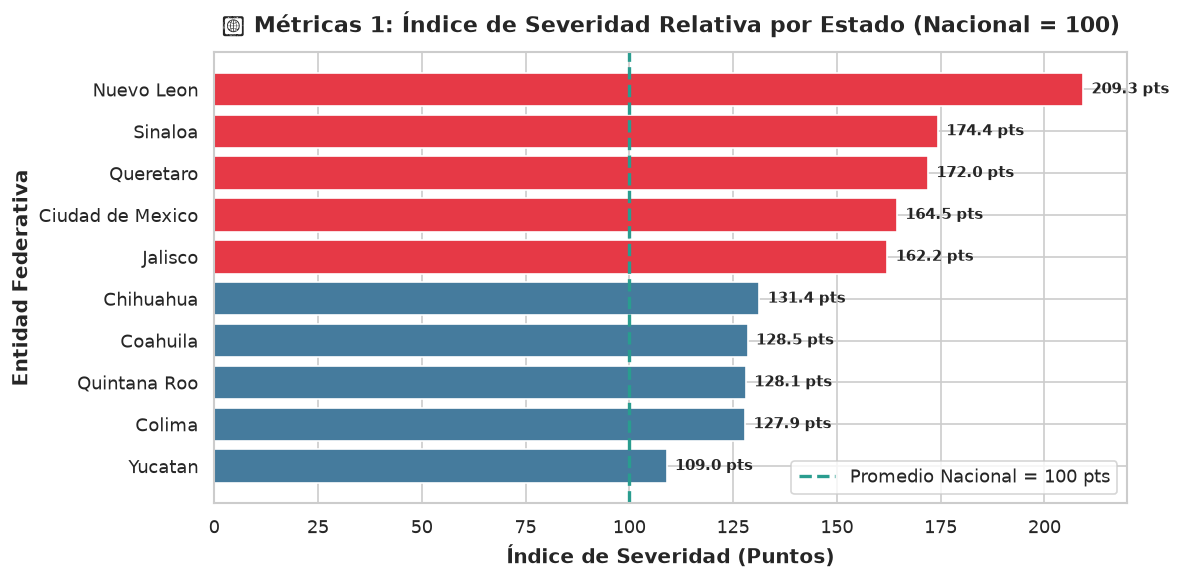

In [7]:
# 7.1 Gráfica 1: Índice de Severidad Relativa por Estado (Base Promedio Nacional = 100)
plt.figure(figsize=(10, 5))
df_top_index = df_resumen_estado.head(10).sort_values(by='indice_severidad', ascending=True)
colors = ['#e63946' if x > 150 else '#457b9d' for x in df_top_index['indice_severidad']]

bars = plt.barh(df_top_index['entidad'], df_top_index['indice_severidad'], color=colors)
plt.axvline(100, color='#2a9d8f', linestyle='--', linewidth=2, label='Promedio Nacional = 100 pts')
plt.title('🎯 Métricas 1: Índice de Severidad Relativa por Estado (Nacional = 100)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Índice de Severidad (Puntos)', fontweight='bold')
plt.ylabel('Entidad Federativa', fontweight='bold')
plt.legend(loc='lower right')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 2, bar.get_y() + bar.get_height()/2, f'{width:.1f} pts', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

/var/folders/9l/y5qn6jxs7tj7ccy7k41hll2w0000gn/T/ipykernel_65949/3150289199.py:14: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


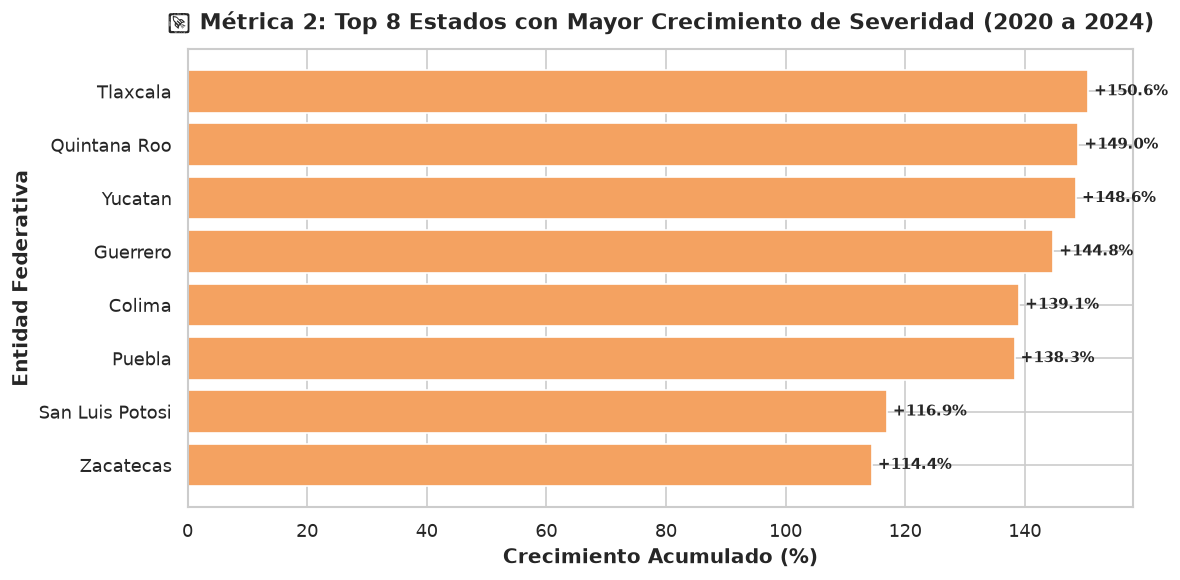

In [8]:
# 7.2 Gráfica 2: Crecimiento Acumulado de Severidad (2020 vs 2024)
plt.figure(figsize=(10, 5))
df_top_growth = df_resumen_estado.sort_values(by='crecimiento_severidad_pct', ascending=True).tail(8)
bars = plt.barh(df_top_growth['entidad'], df_top_growth['crecimiento_severidad_pct'], color='#f4a261')

plt.title('🚀 Métrica 2: Top 8 Estados con Mayor Crecimiento de Severidad (2020 a 2024)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Crecimiento Acumulado (%)', fontweight='bold')
plt.ylabel('Entidad Federativa', fontweight='bold')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2, f'+{width:.1f}%', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

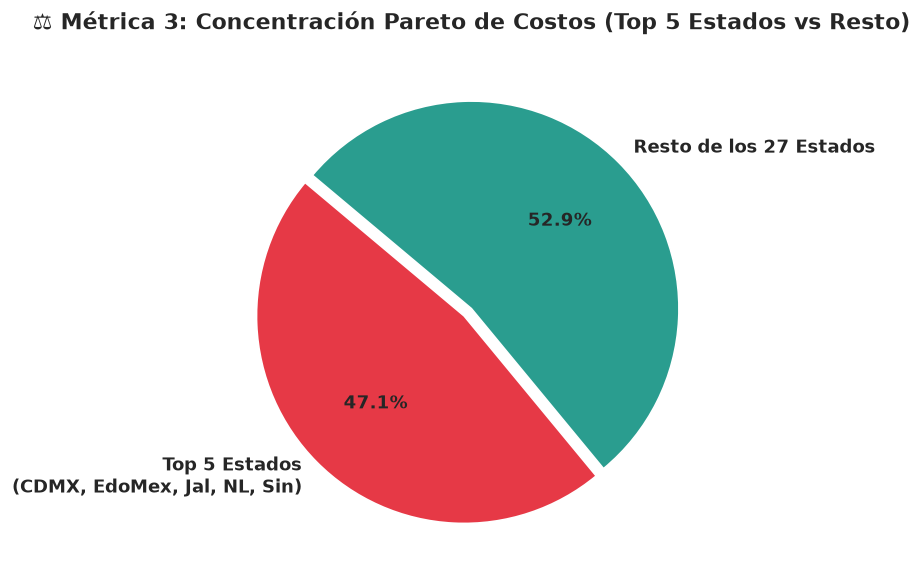

In [9]:
# 7.3 Gráfica 3: Concentración Pareto (Top 5 Estados vs Resto de México)
plt.figure(figsize=(7, 5))
df_top5_cost = df_resumen_estado.sort_values(by='siniestros_ocurridos_mdp', ascending=False).head(5)
top5_sum = df_top5_cost['pct_costo_nacional'].sum()
resto_sum = 100 - top5_sum

labels = ['Top 5 Estados\n(CDMX, EdoMex, Jal, NL, Sin)', 'Resto de los 27 Estados']
sizes = [top5_sum, resto_sum]
colors = ['#e63946', '#2a9d8f']

plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors, textprops={'fontsize': 11, 'fontweight': 'bold'}, explode=(0.05, 0))
plt.title('⚖️ Métrica 3: Concentración Pareto de Costos (Top 5 Estados vs Resto)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

/var/folders/9l/y5qn6jxs7tj7ccy7k41hll2w0000gn/T/ipykernel_65949/2130831464.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_cost_auto, x='costo_por_auto_registrado', y='entidad', palette='Blues_r')


/var/folders/9l/y5qn6jxs7tj7ccy7k41hll2w0000gn/T/ipykernel_65949/2130831464.py:12: UserWarning: Glyph 128664 (\N{ONCOMING AUTOMOBILE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128664 (\N{ONCOMING AUTOMOBILE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


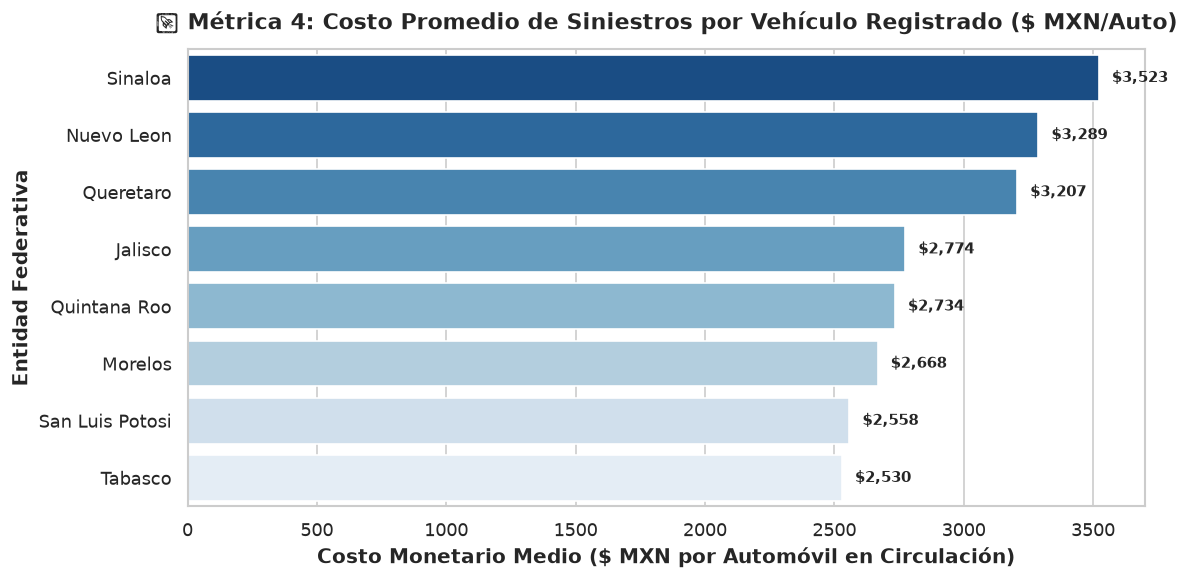

In [10]:
# 7.4 Gráfica 4: Costo Promedio por Automóvil Registrado ($/auto)
plt.figure(figsize=(10, 5))
df_cost_auto = df_resumen_estado.sort_values(by='costo_por_auto_registrado', ascending=False).head(8)
sns.barplot(data=df_cost_auto, x='costo_por_auto_registrado', y='entidad', palette='Blues_r')
plt.title('🚘 Métrica 4: Costo Promedio de Siniestros por Vehículo Registrado ($ MXN/Auto)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Costo Monetario Medio ($ MXN por Automóvil en Circulación)', fontweight='bold')
plt.ylabel('Entidad Federativa', fontweight='bold')

for index, value in enumerate(df_cost_auto['costo_por_auto_registrado']):
    plt.text(value + 50, index, f"${value:,.0f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Conclusiones y Recomendaciones de Negocio

1. **Índice de Riesgo por Estado**: **Nuevo León** ($	ext{Índice} = 209.3$) y **Sinaloa** ($	ext{Índice} = 174.4$) registran más de $1.7$ a $2$ veces la severidad promedio nacional.
2. **Aceleración de Costo (2020-2024)**: Estados como **Querétaro** (+109.2%) y **Nuevo León** (+96.8%) duplicaron el costo medio por reclamo en 5 años.
3. **Concentración Pareto (47.1%)**: 5 estados (**CDMX, EdoMex, Jalisco, NL y Sinaloa**) acumulan casi la mitad del presupuesto nacional de siniestros.
4. **Variable Clave de Suscripción**: El valor comercial del vehículo es el principal predictor de severidad ($r = +0.85$).

## 9. 🤖 Agente de IA Conversacional (Llama-3 LLM & Fuzzy Matching con Resiliencia Ortográfica)

Probamos el Agente de IA que maneja preguntas arbitrarias en español, corrigiendo errores ortográficos (ej. *'Nevo Lion'*, *'Keretaro'*) y respondiendo dudas actuariales:

In [11]:
from src.ai_assistant_llm import LlamaColabDataAgent

# Inicializar Agente de IA
agent = LlamaColabDataAgent()

print("=== PRUEBA DE CONSULTA INTERACTIVA CON IA EN GOOGLE COLAB ===")
print(agent.process_query("Nevo Lion"))                # Typo: Nuevo León
print("\n" + "-"*50 + "\n")
print(agent.process_query("Keretaro costo"))            # Typo: Querétaro
print("\n" + "-"*50 + "\n")
print(agent.process_query("¿Cuáles son los 3 estados con mayor severidad?"))
print("\n" + "-"*50 + "\n")
print(agent.process_query("¿Qué variables tienen mayor impacto?"))

=== PRUEBA DE CONSULTA INTERACTIVA CON IA EN GOOGLE COLAB ===
🤖 **Llama-3 AI Agent (Fuzzy Match Actuarial)**:
  • Estado Detectado: **Nuevo Leon** (Corregido de 'Nevo Lion')
  • Severidad Promedio (2020-2024): **$13,970.61 MXN**
  • Índice Relativo: **209.3 pts** (Promedio Nacional = 100)
  • Severidad en 2024: **$18,804.45 MXN**
  • Costo Anual Medio: **$8,485.28 MDP**

--------------------------------------------------

🤖 **Llama-3 AI Agent (Fuzzy Match Actuarial)**:
  • Estado Detectado: **Queretaro** (Corregido de 'Keretaro costo')
  • Severidad Promedio (2020-2024): **$11,476.31 MXN**
  • Índice Relativo: **172.0 pts** (Promedio Nacional = 100)
  • Severidad en 2024: **$15,404.11 MXN**
  • Costo Anual Medio: **$2,854.03 MDP**

--------------------------------------------------

🤖 **Llama-3 AI Agent (Fuzzy Match Actuarial)**:
  • Estado Detectado: **Sonora** (Corregido de '¿Cuáles son los 3 estados con mayor severidad?')
  • Severidad Promedio (2020-2024): **$7,176.61 MXN**
  • Índ